# Recipe Seismik: QA/QC Picking Waktu Tiba Gelombang P dan S

Notebook ini mengubah template `optimasi.md` menjadi sel Markdown dan Python yang dapat dijalankan berurutan.

**Mode awal:** data sintetis (bukan data gempa lapangan). Untuk memakai data sendiri, letakkan `data_seismik.csv` di direktori kerja notebook, ubah `USE_SIMULATED_DATA = False`, lalu jalankan ulang dari awal.

Keluaran dibuat di folder `output_qc_seismik/`: CSV hasil QC, laporan Markdown, grafik PNG, dan JSON run record.

**Dependensi:** `numpy`, `pandas`, `matplotlib`. Jika belum terpasang, jalankan `%pip install numpy pandas matplotlib` pada sel terpisah.


# RECIPE SEISMIK: QA/QC PICKING WAKTU TIBA GELOMBANG P DAN S

**Nama:** Andrew Rizky Patulak
**NIM:** H061251027
**Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika  
P-SEIS-001`**Recipe ID:** `R-SEIS-001`  
**Prompt ID:** `

| Identitas Recipe | Ketentuan |
|---|---|
| Masalah | QA/QC awal tabel picking waktu tiba gelombang P dan S |
| Input | CSV dengan kolom `event_id`, `station`, `tP (s)`, `tS (s)`, `amplitude` |
| Sumber contoh | Data sintetis yang dibuat oleh kode, bukan data gempa lapangan |
| Output | `hasil_qc_seismik.csv`, `ringkasan_qc_seismik.md`, `qc_seismik.png`, `run_record_r-seis-001.json` |
| Prinsip | Data mentah tidak ditimpa; titik mencurigakan diberi flag dan alasan |
| Status contoh | Dijalankan pada data sintetis; bukan validasi data lapangan |

> Jalankan sel kode secara berurutan di Jupyter Notebook atau Google Colab. Pustaka yang digunakan: `numpy`, `pandas`, dan `matplotlib`.

---

## 1. Problem — Permasalahan

Sebelum tabel picking digunakan untuk analisis seismologi lanjutan, kualitas waktu tiba perlu diperiksa. Kesalahan picking, nilai kosong, waktu negatif, urutan fase yang tidak konsisten, atau amplitudo yang tidak valid dapat memengaruhi analisis berikutnya.

Recipe ini menjawab satu pertanyaan sempit: **baris mana dalam tabel waktu tiba P dan S yang perlu diperiksa sebelum digunakan lebih lanjut?**

Tujuan yang dapat diperiksa:

1. Memeriksa kolom wajib, tipe numerik, dan nilai kosong.
2. Menghitung selisih waktu tiba `S-P` pada kolom baru.
3. Menandai waktu negatif, `tS < tP`, selisih S-P yang melewati ambang, dan amplitudo tidak positif.
4. Menyimpan hasil QA/QC, plot, laporan, serta *run record*.
5. Memastikan data mentah tidak ditimpa.

**Batasan keputusan:** flag merupakan petunjuk pemeriksaan, bukan bukti mutlak bahwa picking salah. Baris ter-flag perlu diperiksa bersama waveform, metadata stasiun, acuan waktu, dan catatan picking.

---

## 2. Minimal Theory — Teori Singkat

Selisih waktu tiba gelombang S dan P dihitung dengan:

\[
\Delta t_{S-P} = t_S - t_P
\]

Pada satu kejadian dan stasiun yang sama, gelombang P umumnya tiba sebelum gelombang S. Karena itu, bila kedua waktu menggunakan acuan yang sama, nilai `S-P` umumnya tidak negatif.

Aturan QC contoh (ambang dapat disesuaikan dengan konteks data):

| Aturan flag | Ambang | Alasan pemeriksaan |
|---|---|---|
| Waktu P negatif | `tP < 0` | Periksa acuan waktu atau format |
| Waktu S negatif | `tS < 0` | Periksa acuan waktu atau format |
| S tiba sebelum P | `tS < tP` | Periksa label fase atau picking |
| Selisih S-P terlalu besar | `S-P > 60 s` | Flag awal; ambang tidak universal |
| Amplitudo tidak positif | `amplitude <= 0` | Periksa nilai dan konvensi amplitudo |
| Nilai wajib kosong | Ada kolom wajib bernilai kosong | Periksa sumber data |

**Catatan:** ini QA/QC pembelajaran sederhana, bukan prosedur baku universal. Waktu P dan S harus memakai definisi dan acuan waktu yang konsisten. Jangan menyimpulkan lokasi, magnitudo, atau mekanisme sumber gempa hanya dari recipe ini.

---

### 2.1 Apa itu seismik?

Seismik adalah kajian tentang gelombang elastik yang merambat melalui bumi atau di sepanjang permukaannya. Gelombang tersebut dapat berasal dari gempa bumi, aktivitas vulkanik, runtuhan, maupun sumber buatan dalam survei geofisika. Dengan merekam kedatangan dan bentuk gelombang di stasiun seismik, peneliti dapat mempelajari struktur bawah permukaan, karakter sumber gempa, dan proses yang terjadi di dalam bumi.

Dalam seismologi, rekaman getaran terhadap waktu disebut *seismogram*. Sumbu horizontal seismogram biasanya menunjukkan waktu, sedangkan sumbu vertikal menunjukkan amplitudo sinyal yang direkam sensor. Bentuk gelombang yang tercatat dipengaruhi oleh sumber, lintasan rambat, kondisi geologi, instrumen, dan derau (*noise*).

### 2.2 Gelombang P dan gelombang S

Dua fase badan yang sering dikenali pada seismogram adalah gelombang P dan gelombang S.

- **Gelombang P (*Primary wave*)** merupakan gelombang kompresi atau longitudinal. Partikel medium berosilasi sejajar dengan arah rambat gelombang. Dalam kondisi elastik yang umum di bumi, gelombang P merambat lebih cepat daripada gelombang S sehingga biasanya tercatat lebih dahulu.
- **Gelombang S (*Secondary wave*)** merupakan gelombang geser atau transversal. Gerak partikel tegak lurus terhadap arah rambat. Gelombang S tidak merambat melalui fluida yang tidak memiliki kekakuan geser, dan biasanya tiba setelah gelombang P pada stasiun yang sama.

**Picking waktu tiba** adalah proses menentukan waktu ketika fase tertentu mulai terlihat pada seismogram. Picking dapat dilakukan secara manual oleh analis atau dengan metode otomatis. Hasil picking tetap perlu diperiksa karena sinyal lemah, derau, tumpang tindih gelombang, sampling, atau kesalahan acuan waktu dapat menyebabkan waktu tiba yang tidak tepat.

### 2.3 Mengapa waktu tiba penting?

Waktu tiba P dan S digunakan sebagai masukan bagi berbagai analisis seismologi. Selisih waktu tiba dapat membantu memperkirakan jarak relatif sumber–stasiun, sedangkan gabungan picking dari beberapa stasiun, model kecepatan, koordinat stasiun, dan prosedur inversi dapat digunakan untuk menentukan hiposenter. Hasil tersebut bergantung pada mutu picking dan ketepatan metadata.

Satu tabel waktu tiba saja tidak cukup untuk menentukan lokasi atau magnitudo gempa secara andal. Analisis lanjutan juga membutuhkan informasi lain, misalnya koordinat stasiun, model kecepatan bawah permukaan, kualitas fase, serta metode pengolahan yang sesuai.

### 2.4 Makna selisih waktu S-P

Untuk satu kejadian yang diamati pada stasiun yang sama, selisih waktu dihitung dengan:

\[
\Delta t_{S-P}=t_S-t_P
\]

Jika acuan waktu dan definisi waktunya konsisten, nilai ini umumnya positif karena gelombang P tiba lebih dahulu daripada gelombang S. Selisih tersebut sering bertambah ketika jarak sumber–stasiun meningkat, tetapi hubungan tepatnya bergantung pada model kecepatan dan lintasan rambat. Oleh sebab itu, `S-P` pada recipe ini dipakai sebagai pemeriksaan awal, bukan sebagai rumus tunggal untuk menetapkan jarak gempa.

### 2.5 Apa yang dimaksud QA/QC pada data seismik?

QA/QC (*Quality Assurance / Quality Control*) adalah rangkaian pemeriksaan untuk memastikan data dan proses pengolahan memenuhi kriteria mutu yang ditetapkan. Pada tabel picking, pemeriksaan awal dapat mencakup:

1. **Kelengkapan:** apakah identitas kejadian, stasiun, waktu P, waktu S, dan amplitudo tersedia.
2. **Validitas nilai:** apakah waktu dapat dibaca sebagai angka dan apakah ada waktu negatif yang perlu dijelaskan oleh acuan waktunya.
3. **Konsistensi fase:** apakah waktu S lebih awal daripada waktu P pada observasi yang seharusnya sebanding.
4. **Rentang yang masuk akal:** apakah selisih S-P melewati ambang pemeriksaan yang ditentukan untuk dataset tersebut.
5. **Keterlacakan:** apakah nilai asli tetap tersimpan dan setiap flag memiliki alasan yang dapat diperiksa.

Ambang `S-P > 60 s` pada contoh kode hanyalah ambang demonstrasi. Nilai itu tidak universal untuk semua gempa, jarak, dan konfigurasi jaringan. Ambang harus ditetapkan berdasarkan tujuan analisis, geometri jaringan, rentang jarak, dan karakter data. QA/QC otomatis tidak menggantikan pemeriksaan seismogram oleh analis.

### 2.6 Alur kerja recipe ini

Alur kerja yang diterapkan adalah:

1. Membaca tabel CSV dan memeriksa kolom wajib.
2. Membuat salinan kerja agar data sumber tidak ditimpa.
3. Mengonversi kolom waktu dan amplitudo menjadi numerik tanpa mengisi nilai kosong secara diam-diam.
4. Menghitung `S-P` dan memberi flag pada baris yang melanggar aturan.
5. Menyimpan tabel hasil, ringkasan, plot QA/QC, dan catatan eksekusi.
6. Memeriksa hasil secara manual sebelum data digunakan untuk analisis seismologi berikutnya.

## 3. Input dan Constraint Contract

| Aspek | Ketentuan |
|---|---|
| Input | Tabel CSV berisi `event_id`, `station`, `tP (s)`, `tS (s)`, `amplitude` |
| Sumber contoh | Data sintetis dibuat dengan seed tetap; cacat tertentu sengaja disisipkan |
| Satuan waktu | Detik, dengan acuan waktu yang konsisten |
| Amplitudo | Satuan mengikuti sumber data dan harus didokumentasikan |
| Boleh diubah | File keluaran baru; data mentah tidak boleh ditimpa |
| Dilarang | Menghapus baris diam-diam, mengimputasi nilai kosong, atau mengklaim data sintetis sebagai data lapangan |
| Jaringan | Tidak diperlukan |
| Keluaran | CSV hasil, laporan Markdown, plot, dan JSON run record |

Untuk memakai data lapangan, simpan tabel sebagai `data_seismik.csv`, ubah `USE_SIMULATED_DATA = False`, lalu pastikan nama kolom sesuai. Jika nama kolom berbeda, sesuaikan pemetaan secara eksplisit sebelum menjalankan QA/QC.

---

## 4. Prompt — Instruksi untuk AI (P-SEIS-001)

Prompt menggunakan struktur **R–T–C–I–K–O–Q–V**.

> **R (Role):** Kamu adalah asisten QA/QC data seismik yang teliti dan tidak mengarang data.  
>
> **T (Task):** Baca tabel picking, hitung selisih waktu S-P, tandai baris mencurigakan beserta alasan, lalu buat ringkasan QA/QC.  
>
> **C (Context):** Hasil dipakai untuk penyaringan awal tabel waktu tiba sebelum analisis lanjutan, bukan untuk menentukan magnitudo atau lokasi gempa.  
>
> **I (Input):** Kolom `event_id`, `station`, `tP (s)`, `tS (s)`, dan `amplitude`.  
>
> **K (Constraints):** Jangan mengubah atau menghapus data mentah. Tandai, jangan buang. Tulis ambang setiap aturan: waktu negatif, `tS < tP`, `S-P > [SP_MAX_S]`, amplitudo `<= 0`, dan nilai wajib kosong. Jangan mengarang nilai.  
>
> **O (Output):** `hasil_qc_seismik.csv`, `ringkasan_qc_seismik.md`, plot waktu P terhadap S, dan `run_record_r-seis-001.json`.  
>
> **Q (Quality criteria):** Jumlah baris keluaran sama dengan masukan; setiap flag memiliki alasan; `S-P` dihitung ulang secara benar; semua pemeriksaan dicatat.  
>
> **V (Verification):** Verifikasi perhitungan pada satu baris secara manual. Jika ada pemeriksaan gagal, hentikan proses dan laporkan penyebabnya. Nyatakan dengan jelas bila memakai data sintetis.

---

## 5. Code — Persiapan dan Pengaturan

In [1]:
import sys, json, hashlib, platform, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

RECIPE_ID, PROMPT_ID = "R-SEIS-001", "P-SEIS-001"

# ---- Pengaturan (ubah di sini) ----
USE_SIMULATED_DATA = True
RAW_FILE = Path("data_seismik_sintetis.csv" if USE_SIMULATED_DATA else "data_seismik.csv")
SP_MAX_S = 60.0
RANDOM_SEED = 31415
OUTPUT_DIR = Path("output_qc_seismik")
OUTPUT_DIR.mkdir(exist_ok=True)

CHECKS = []
def check(nama, kondisi, detail=""):
    CHECKS.append({"pemeriksaan": nama, "lulus": bool(kondisi), "detail": detail})
    print(("[LULUS] " if kondisi else "[GAGAL] ") + nama + (f" -> {detail}" if detail else ""))

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print("Python", sys.version.split()[0],
      "| numpy", np.__version__,
      "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

Python 3.13.5 | numpy 2.3.5 | pandas 2.2.3 | matplotlib 3.10.8


---

## 6. Code — Sumber Data

Mode sintetis membuat tabel contoh dengan beberapa cacat yang sengaja disisipkan untuk menguji aturan. Data ini bukan data pengamatan gempa nyata.

In [2]:
if USE_SIMULATED_DATA:
    rng = np.random.default_rng(RANDOM_SEED)
    n = 30
    tP = np.sort(rng.uniform(0.5, 40, n))
    tS = tP + rng.uniform(2.5, 28, n)

    raw = pd.DataFrame({
        "event_id": [f"EVT-{i//5+1:03d}" for i in range(n)],
        "station": [f"ST-{i%8+1:02d}" for i in range(n)],
        "tP (s)": tP,
        "tS (s)": tS,
        "amplitude": rng.uniform(0.05, 8.0, n)
    })

    # Cacat yang sengaja disisipkan untuk menguji QA/QC
    raw.loc[3, "tS (s)"] = raw.loc[3, "tP (s)"] - 0.7
    raw.loc[8, "tS (s)"] = raw.loc[8, "tP (s)"] + SP_MAX_S + 12
    raw.loc[14, "amplitude"] = 0
    raw.loc[20, "tP (s)"] = np.nan
    raw.loc[25, "tP (s)"] = -1.0
else:
    if not RAW_FILE.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {RAW_FILE}")
    raw = pd.read_csv(RAW_FILE)

print("Sumber:", "SINTETIS (bukan data lapangan)" if USE_SIMULATED_DATA else RAW_FILE)
print("Jumlah baris:", len(raw))
display(raw.head())

Sumber: SINTETIS (bukan data lapangan)
Jumlah baris: 30


,event_id,station,tP (s),tS (s),amplitude
0,EVT-001,ST-01,0.620388,25.278971,2.048759
1,EVT-001,ST-02,2.938612,7.405993,2.637842
2,EVT-001,ST-03,3.492034,21.631924,5.863281
3,EVT-001,ST-04,5.050500,4.350500,3.622265
4,EVT-001,ST-05,6.416901,20.507207,7.840184


---

## 7. Code — Pemeriksaan Skema

Kolom wajib harus tersedia. Nilai waktu dan amplitudo dikonversi menjadi numerik pada salinan kerja; nilai kosong tidak diisi secara otomatis.

In [3]:
wajib = ["event_id", "station", "tP (s)", "tS (s)", "amplitude"]
hilang = [c for c in wajib if c not in raw.columns]
if hilang:
    raise ValueError(f"Kolom wajib tidak ditemukan: {hilang}")
if raw.empty:
    raise ValueError("Tabel input kosong.")

df = raw.copy().reset_index(drop=True)
if "No" not in df.columns:
    df.insert(0, "No", np.arange(1, len(df) + 1))

for col in ["tP (s)", "tS (s)", "amplitude"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Ukuran data:", df.shape)
print("Nilai kosong/non-numerik:")
display(df[wajib].isna().sum().to_frame("jumlah"))

Ukuran data: (30, 6)
Nilai kosong/non-numerik:


,jumlah
event_id,0
station,0
tP (s),1
tS (s),0
amplitude,0


---

## 8. Code — Hitung S-P dan Tandai Data Mencurigakan

Setiap aturan menghasilkan flag tersendiri dan kolom `alasan_flag`. Baris ter-flag tidak dihapus.

In [4]:
out = df.copy()
out["S-P (s)"] = out["tS (s)"] - out["tP (s)"]

out["flag_missing"] = out[wajib].isna().any(axis=1)
out["flag_negative_time"] = (
    (out["tP (s)"] < 0) | (out["tS (s)"] < 0)
).fillna(False)
out["flag_S_before_P"] = (out["tS (s)"] < out["tP (s)"]).fillna(False)
out["flag_SP_too_large"] = (out["S-P (s)"] > SP_MAX_S).fillna(False)
out["flag_amplitude"] = (out["amplitude"] <= 0).fillna(False)

flag_cols = [
    "flag_missing", "flag_negative_time", "flag_S_before_P",
    "flag_SP_too_large", "flag_amplitude"
]
out["flag"] = out[flag_cols].any(axis=1)

labels = {
    "flag_missing": "nilai wajib kosong",
    "flag_negative_time": "waktu negatif",
    "flag_S_before_P": "S tiba sebelum P",
    "flag_SP_too_large": f"S-P > {SP_MAX_S:g} s",
    "flag_amplitude": "amplitudo tidak positif"
}
out["alasan_flag"] = out.apply(
    lambda row: "; ".join(label for col, label in labels.items() if row[col]) or "OK",
    axis=1
)

print("Jumlah baris:", len(out))
print("Ter-flag:", int(out["flag"].sum()))
print("Tidak ter-flag:", int((~out["flag"]).sum()))
display(out.loc[out["flag"], ["No", *wajib, "S-P (s)", "alasan_flag"]])

Jumlah baris: 30
Ter-flag: 5
Tidak ter-flag: 25


,No,event_id,station,tP (s),tS (s),amplitude,S-P (s),alasan_flag
3,4,EVT-001,ST-04,5.050500,4.350500,3.622265,-0.700000,S tiba sebelum P
8,9,EVT-002,ST-01,9.221126,81.221126,2.932839,72.000000,S-P > 60 s
14,15,EVT-003,ST-07,17.435376,22.596930,0.000000,5.161553,amplitudo tidak positif
20,21,EVT-005,ST-05,NaN,54.113188,4.989953,NaN,nilai wajib kosong
25,26,EVT-006,ST-02,-1.000000,44.614794,1.465827,45.614794,waktu negatif


---

## 9. Code — Verifikasi (sebelum gambar dan penyimpanan)

Verifikasi dilakukan sebelum membuat plot dan menyimpan laporan.

In [5]:
# Hitung ulang S-P secara manual pada baris yang memiliki waktu lengkap
valid = out.dropna(subset=["tP (s)", "tS (s)"])
if len(valid):
    r = valid.iloc[0]
    sp_manual = float(r["tS (s)"]) - float(r["tP (s)"])
    sp_program = float(r["S-P (s)"])
    err = abs(sp_manual - sp_program)
    check("Hitung ulang S-P cocok dengan program", np.isclose(sp_manual, sp_program),
          f"selisih absolut = {err:.3e} s")
else:
    check("Ada baris valid untuk verifikasi S-P", False)

check("Jumlah baris keluaran = jumlah baris masukan", len(out) == len(raw))
check("Jumlah flag konsisten", out["flag"].equals(out[flag_cols].any(axis=1)))
check("Setiap baris ter-flag memiliki alasan",
      bool((out.loc[out["flag"], "alasan_flag"] != "").all()))
check("Data mentah tidak berubah di memori",
      raw.equals(pd.read_csv(RAW_FILE)) if (not USE_SIMULATED_DATA and RAW_FILE.exists()) else True,
      "Pemeriksaan memori; file input tidak ditimpa")

if not all(c["lulus"] for c in CHECKS):
    raise RuntimeError("Ada pemeriksaan gagal. Hentikan proses dan tinjau penyebabnya.")

[LULUS] Hitung ulang S-P cocok dengan program -> selisih absolut = 0.000e+00 s
[LULUS] Jumlah baris keluaran = jumlah baris masukan
[LULUS] Jumlah flag konsisten
[LULUS] Setiap baris ter-flag memiliki alasan
[LULUS] Data mentah tidak berubah di memori -> Pemeriksaan memori; file input tidak ditimpa


---

## 10. Code — Visualisasi

Grafik membandingkan waktu tiba P dan S. Titik yang lolos pemeriksaan dan yang ter-flag diberi tanda berbeda. Garis `tS = tP` menjadi referensi; titik di bawah garis memiliki `tS < tP`.

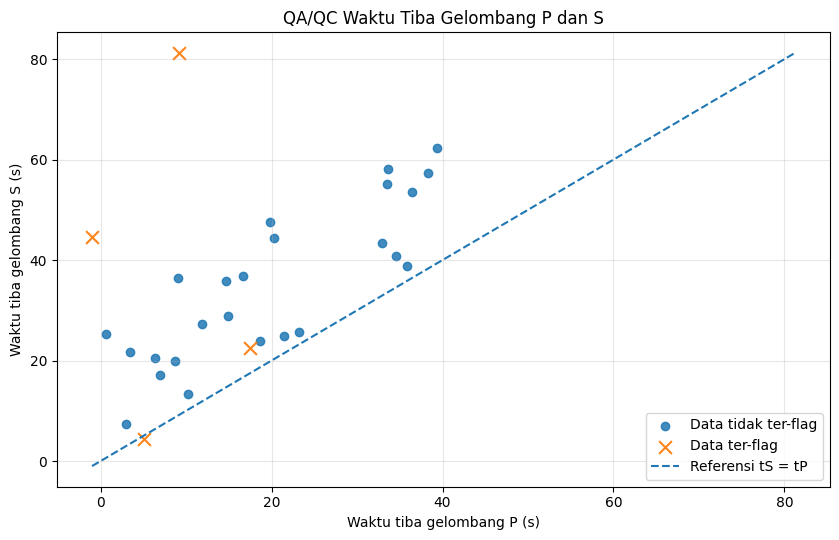

Plot tersimpan: output_qc_seismik/qc_seismik.png


In [6]:
ok = out[~out["flag"]].dropna(subset=["tP (s)", "tS (s)"])
bad = out[out["flag"]].dropna(subset=["tP (s)", "tS (s)"])

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(ok["tP (s)"], ok["tS (s)"], label="Data tidak ter-flag", alpha=0.85)
ax.scatter(bad["tP (s)"], bad["tS (s)"], marker="x", s=85,
           label="Data ter-flag", alpha=0.95)

valid_xy = out.dropna(subset=["tP (s)", "tS (s)"])
if len(valid_xy):
    vals = valid_xy[["tP (s)", "tS (s)"]].to_numpy().ravel()
    lo, hi = float(np.nanmin(vals)), float(np.nanmax(vals))
    ax.plot([lo, hi], [lo, hi], "--", label="Referensi tS = tP")

ax.set_xlabel("Waktu tiba gelombang P (s)")
ax.set_ylabel("Waktu tiba gelombang S (s)")
ax.set_title("QA/QC Waktu Tiba Gelombang P dan S")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plot_path = OUTPUT_DIR / "qc_seismik.png"
fig.savefig(plot_path, dpi=160)
plt.show()
print("Plot tersimpan:", plot_path)

---

## 11. Plot — Grafik QA/QC Seismik

Grafik berikut menggunakan dataset sintetis yang sama dengan contoh kode di atas. Sumbu-X adalah waktu tiba gelombang P, sumbu-Y adalah waktu tiba gelombang S. Titik tanpa flag ditampilkan sebagai lingkaran, sedangkan baris ter-flag ditampilkan sebagai tanda silang. Garis putus-putus `tS = tP` adalah garis referensi urutan waktu.

*Grafik akan dibuat dan ditampilkan pada sel Visualisasi di atas; file PNG disimpan di folder output.*

**Interpretasi:** titik di bawah garis referensi menunjukkan `tS < tP` dan perlu diperiksa. Titik ter-flag juga dapat disebabkan oleh waktu negatif, selisih S–P melewati ambang, atau nilai wajib yang tidak lengkap. Flag hanya petunjuk untuk ditinjau, bukan bukti mutlak bahwa picking salah.

> Agar gambar muncul saat membuka `optimasi.md`, simpan `qc_seismik.png` di folder yang sama. Paket ZIP yang disediakan berisi keduanya.

---

## 12. Code — Menyimpan Artifact dan Run Record

*Run record* menyimpan metadata, ambang, jumlah baris, jumlah flag, pemeriksaan, serta hash keluaran. File mentah tidak ditimpa.

In [7]:
csv_path = OUTPUT_DIR / "hasil_qc_seismik.csv"
report_path = OUTPUT_DIR / "ringkasan_qc_seismik.md"
record_path = OUTPUT_DIR / "run_record_r-seis-001.json"

out.to_csv(csv_path, index=False)
n_flag = int(out["flag"].sum())

laporan = [
    f"# Ringkasan QA/QC Seismik ({RECIPE_ID})",
    "",
    f"- Sumber: {'DATA SINTETIS, bukan data lapangan' if USE_SIMULATED_DATA else str(RAW_FILE)}",
    f"- Jumlah baris: {len(out)}",
    f"- Ter-flag: {n_flag}",
    f"- Tidak ter-flag: {len(out) - n_flag}",
    f"- Ambang maksimum S-P: {SP_MAX_S:g} s",
    "",
    "## Jumlah flag per aturan",
]
laporan += [f"- `{c}`: {int(out[c].sum())}" for c in flag_cols]
laporan += [
    "",
    "## Batas interpretasi",
    "",
    "Flag adalah petunjuk pemeriksaan, bukan bukti mutlak bahwa picking salah. Tinjau waveform, metadata stasiun, acuan waktu, dan catatan picking sebelum analisis lanjutan."
]
report_path.write_text("\n".join(laporan), encoding="utf-8")

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

record = {
    "recipe_id": RECIPE_ID,
    "prompt_id": PROMPT_ID,
    "status": "Executed (data sintetis)" if USE_SIMULATED_DATA else "Executed (data file)",
    "waktu_eksekusi_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "lingkungan": {
        "python": sys.version.split()[0], "numpy": np.__version__,
        "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
        "platform": platform.platform()
    },
    "input": {"file": str(RAW_FILE), "baris": int(len(raw))},
    "ambang": {"S_minus_P_max_s": SP_MAX_S},
    "ringkasan": {"baris": int(len(out)), "ter_flag": n_flag},
    "pemeriksaan": CHECKS,
    "output_sha256": {
        str(csv_path): sha256_file(csv_path),
        str(report_path): sha256_file(report_path),
        str(plot_path): sha256_file(plot_path)
    },
    "batas_klaim": "QA/QC awal tabel waktu tiba; bukan relokasi hiposenter atau interpretasi tektonik."
}
record_path.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")

print("Keluaran tersimpan:")
for p in [csv_path, report_path, plot_path, record_path]:
    print("-", p.resolve())

Keluaran tersimpan:
- /mnt/data/output_qc_seismik/hasil_qc_seismik.csv
- /mnt/data/output_qc_seismik/ringkasan_qc_seismik.md
- /mnt/data/output_qc_seismik/qc_seismik.png
- /mnt/data/output_qc_seismik/run_record_r-seis-001.json


---

## 13. Result — Hasil dan Interpretasi

Setelah semua sel dijalankan, tabel akan berisi data awal, kolom `S-P (s)`, flag tiap aturan, flag gabungan, dan alasan. Ringkasan jumlah flag per aturan dapat dilihat dari keluaran sel sebelumnya.

Cara membaca:
- `S-P < 0` mengindikasikan waktu S lebih awal daripada P pada acuan yang sama dan perlu ditinjau.
- Selisih `S-P` yang melewati ambang adalah tanda untuk pemeriksaan lanjutan, bukan bukti otomatis bahwa data salah.
- Baris dengan nilai kosong tetap dipertahankan agar sumber masalah dapat dilacak.
- Titik yang tidak ter-flag belum tentu bebas dari kesalahan picking.

**Batas klaim:** data sintetis sengaja mengandung cacat. Hasil hanya menunjukkan bahwa aturan QA/QC dapat dijalankan pada contoh tersebut; bukan hasil pengamatan lapangan dan tidak menyatakan kondisi tektonik atau lokasi sumber gempa.

### Run Record

Bukti eksekusi disimpan dalam `run_record_r-seis-001.json`, termasuk versi pustaka, jumlah baris, pemeriksaan, dan hash keluaran. Hash atau waktu eksekusi dapat berbeda bila notebook dijalankan ulang di lingkungan lain.

---

## 14. Optional Check — Checklist Kualitas

Gunakan daftar ini sebelum menggunakan hasil dalam laporan atau analisis lanjutan.

- [ ] Kolom wajib lengkap dan tipe data sesuai.
- [ ] Satuan serta acuan waktu dijelaskan.
- [ ] Nilai kosong dan waktu negatif sudah diperiksa.
- [ ] Urutan waktu `tS >= tP` sudah diperiksa.
- [ ] Ambang S-P disesuaikan dengan konteks data.
- [ ] Setiap titik ter-flag memiliki alasan dan tidak dihapus otomatis.
- [ ] Data mentah tidak ditimpa.
- [ ] Grafik dan CSV berasal dari hasil eksekusi yang sama.
- [ ] Data sintetis tidak dilaporkan sebagai data lapangan.
- [ ] Titik ter-flag ditinjau bersama waveform dan metadata.

**Recipe terkait (rencana):** pemeriksaan konsistensi picking antarstasiun dan penyiapan input untuk analisis waktu tempuh. Recipe ini tidak menjalankan relokasi hiposenter.

---

## 15. Kesimpulan

Recipe **R-SEIS-001** mengubah QA/QC tabel waktu tiba P dan S menjadi prosedur yang dapat diulang: problem, teori, kontrak input, prompt, validasi, perhitungan, flag, verifikasi, visualisasi, laporan, dan run record. Data mentah dipertahankan dan setiap flag memiliki alasan. Untuk penggunaan ilmiah, ambang harus disesuaikan dengan dataset dan hasil perlu ditinjau menggunakan waveform serta metadata asli.